<a href="https://colab.research.google.com/github/d-selver/bist-risk-analysis/blob/main/bist_risk_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
!pip install -q yfinance
import yfinance as yf

lst = ["BIMAS.IS", "MGROS.IS", "SOKM.IS", "XU100.IS"]

data = yf.download(lst,period="3y", auto_adjust= True)

price = data["Close"]

print(price.isna().sum())

[*********************100%***********************]  4 of 4 completed


Ticker
BIMAS.IS    0
MGROS.IS    1
SOKM.IS     1
XU100.IS    3
dtype: int64


In [27]:
clean = price.dropna()
daily_returns = clean.pct_change().dropna() #percentage change since yesterday
print(daily_returns.head())


Ticker      BIMAS.IS  MGROS.IS   SOKM.IS  XU100.IS
Date                                              
2023-11-28 -0.016381  0.000665 -0.007589 -0.001690
2023-11-29 -0.010309 -0.025931 -0.019541 -0.010403
2023-11-30 -0.012820 -0.017747  0.014731 -0.007579
2023-12-01 -0.008117 -0.021543 -0.002562  0.009775
2023-12-04  0.007365 -0.014915  0.023973  0.007588


In [28]:
import numpy as np
annual_vol = daily_returns.std()* np.sqrt(252)
annual_vol = annual_vol * 100
print(annual_vol.round(2))


Ticker
BIMAS.IS    36.05
MGROS.IS    34.50
SOKM.IS     36.93
XU100.IS    24.56
dtype: float64


In [29]:
peak = clean.cummax()
drawdown = (clean / peak)-1
min_drawdown = drawdown.min()
min_drawdown *= 100
print(min_drawdown.round(2))

Ticker
BIMAS.IS   -33.47
MGROS.IS   -44.05
SOKM.IS    -54.34
XU100.IS   -29.59
dtype: float64


In [30]:
market_var = daily_returns["XU100.IS"].var()
beta = daily_returns.cov()["XU100.IS"] / market_var
print(beta.round(2))

Ticker
BIMAS.IS    0.93
MGROS.IS    0.83
SOKM.IS     0.90
XU100.IS    1.00
Name: XU100.IS, dtype: float64


In [31]:
import sqlite3
import pandas as pd

table = daily_returns.reset_index().melt(
    id_vars="Date", var_name="ticker", value_name="daily_return")
connection = sqlite3.connect("bist.db")
table.to_sql("returns", connection, if_exists="replace", index=False)

query = """
SELECT ticker,
  MIN(daily_return) AS worst_day,
  MAX(daily_return) AS best_day
FROM returns
GROUP BY ticker
"""
print(pd.read_sql(query, connection))

     ticker  worst_day  best_day
0  BIMAS.IS  -0.099802  0.099638
1  MGROS.IS  -0.092064  0.099874
2   SOKM.IS  -0.100000  0.099940
3  XU100.IS  -0.087195  0.060577


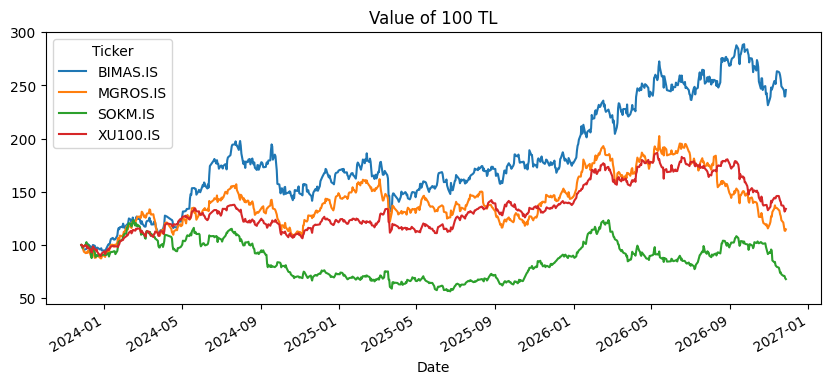

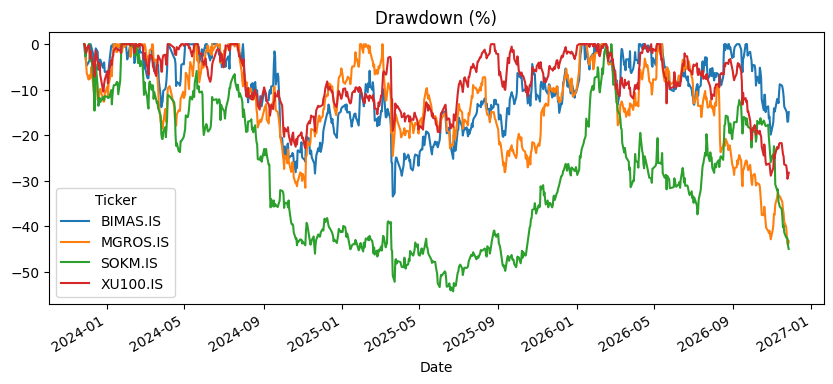

In [32]:
import matplotlib.pyplot as plt
"""
I normalized their adjusted closing prices to an initial value of 100 TL to compare te performance of the stocks
"""
value = clean / clean.iloc[0] * 100

value.plot(figsize=(10, 4), title="Value of 100 TL")
plt.show()

pict_of_drawdown = drawdown * 100

pict_of_drawdown.plot(figsize=(10, 4), title="Drawdown (%)")
plt.show()

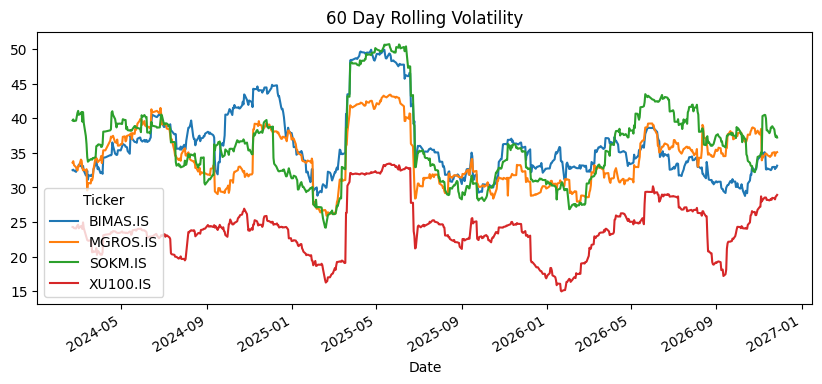

In [33]:
last_60_day = daily_returns.rolling(60).std()
rolling_vol = last_60_day * np.sqrt(252) * 100
rolling_vol.plot(figsize=(10, 4), title="60 Day Rolling Volatility")
plt.show()

In [34]:
years = len(daily_returns) / 252
annual_return = ((clean.iloc[-1]/clean.iloc[0]) ** (1/years)) -1
print((annual_return *100).round(2))

Ticker
BIMAS.IS    35.38
MGROS.IS     4.72
SOKM.IS    -12.23
XU100.IS    10.35
dtype: float64


# Methodology
Daily returns are calculated using percentage changes in adjusted closing prices.

Annual volatility is calculated using the standart deviation of daily returns multiplied by the suare root of 252 which is the number of trading days.

Beta is estimated using the covariance between each stock's daily returns and the BIST100 returns by dividing it with the variance of the benchmark.

Maxiumum drawdown is calculated by comparing prices with their historical running maximum.

# Limitations
The analysis has some limitations:


*   Historical Performance does not guarantee future results.
*   Transaction costs, taxes and inflation are not included.

